# Detection Windows: $\alpha^*(\epsilon)$ vs $\epsilon$

Reproduces Figure 1 of the paper (two panels).

**Example A (Well-mixed):** $P_A$ with swap internal block  
**Example B (Starved):** $P_B$ with starved-node internal block  

All curves are closed-form from the paper (no simulation needed).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif",
    "mathtext.fontset": "cm",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

COLOR_PR  = '#5b9bd5'   # blue
COLOR_PPR = '#e05c4b'   # red

SAVE_FIGS = False
FIG_DIR   = 'figures/'

import os; os.makedirs(FIG_DIR, exist_ok=True)
print("Setup done.")


Setup done.


## Example A: Well-mixed internal block  ($\beta = 1/2$)

Closed-form detection windows (eq. A-PR-star, A-PPR-star):

$$\alpha^*_{\mathrm{PR}}(\epsilon) = 1 - 8\epsilon, \qquad
\epsilon^{\max}_{\mathrm{PR}} = 1/8$$

$$\alpha^*_{\mathrm{PPR}}(\epsilon) = \frac{1-4\epsilon}{1+4\epsilon}, \qquad
\epsilon^{\max}_{\mathrm{PPR}} = 1/4$$


In [2]:
eps_A_PR  = np.linspace(0, 1/8,  500)
eps_A_PPR = np.linspace(0, 1/4,  500)

alpha_A_PR  = np.maximum(0, 1 - 8*eps_A_PR)
alpha_A_PPR = np.maximum(0, (1 - 4*eps_A_PPR) / (1 + 4*eps_A_PPR))

print(f"Example A:")
print(f"  eps_max (PR)  = 1/8  = {1/8:.4f}")
print(f"  eps_max (PPR) = 1/4  = {1/4:.4f}")
print(f"  PPR/PR advantage: {(1/4)/(1/8):.1f}x")


Example A:
  eps_max (PR)  = 1/8  = 0.1250
  eps_max (PPR) = 1/4  = 0.2500
  PPR/PR advantage: 2.0x


## Example B: Starved internal block  ($\beta = 1/2$)

Closed-form detection windows (eq. B-PR-star, B-PPR-star):

$$\alpha^*_{\mathrm{PR}}(\epsilon) = \max\!\bigl(0,\; 1 - \sqrt{24\epsilon}\bigr),
\qquad \epsilon^{\max}_{\mathrm{PR}} = 1/24 \approx 0.0417$$

$$\alpha^*_{\mathrm{PPR}}(\epsilon) = \begin{cases}
(1+2\epsilon) - 2\sqrt{\epsilon(1+\epsilon)} & \epsilon \le 1/8 \\
1 - 4\epsilon & \epsilon \ge 1/8
\end{cases}, \qquad \epsilon^{\max}_{\mathrm{PPR}} = 1/4$$


In [3]:
eps_B_PR  = np.linspace(0, 1/24, 500)
eps_B_PPR = np.linspace(0, 1/4,  500)

alpha_B_PR  = np.maximum(0, 1 - np.sqrt(24 * eps_B_PR))

# PPR: two branches joined at eps = 1/8
def alpha_B_PPR_func(eps):
    alpha = np.where(
        eps <= 1/8,
        (1 + 2*eps) - 2*np.sqrt(eps * (1 + eps)),   # upper branch
        np.maximum(0, 1 - 4*eps)                      # lower branch
    )
    return alpha

alpha_B_PPR = alpha_B_PPR_func(eps_B_PPR)

print(f"Example B:")
print(f"  eps_max (PR)  = 1/24 = {1/24:.4f}")
print(f"  eps_max (PPR) = 1/4  = {1/4:.4f}")
print(f"  PPR/PR advantage: {(1/4)/(1/24):.1f}x")
print(f"  Branch junction: eps=1/8={1/8:.4f}, alpha=0.5")


Example B:
  eps_max (PR)  = 1/24 = 0.0417
  eps_max (PPR) = 1/4  = 0.2500
  PPR/PR advantage: 6.0x
  Branch junction: eps=1/8=0.1250, alpha=0.5


## Figure: Detection windows (two panels)

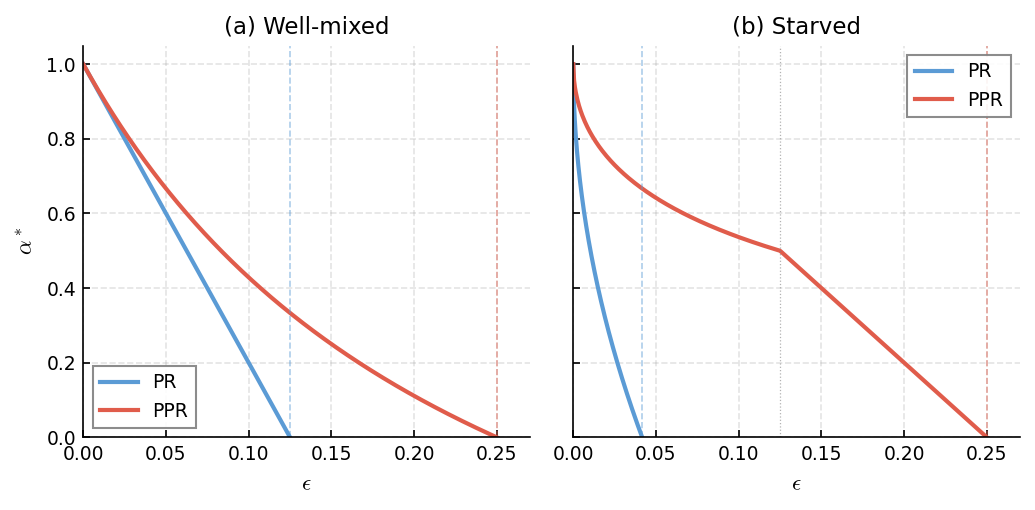

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True)

# ── Panel (a): Well-mixed ─────────────────────────────────────────────────────
ax = axes[0]
ax.plot(eps_A_PR,  alpha_A_PR,  color=COLOR_PR,  lw=2.0, label='PR')
ax.plot(eps_A_PPR, alpha_A_PPR, color=COLOR_PPR, lw=2.0, label='PPR')

ax.axvline(1/8, color=COLOR_PR,  lw=0.8, ls='--', alpha=0.5)
ax.axvline(1/4, color=COLOR_PPR, lw=0.8, ls='--', alpha=0.5)

ax.set_xlabel(r'$\epsilon$')
ax.set_ylabel(r'$\alpha^*$')
ax.set_title('(a) Well-mixed')
ax.set_xlim(0, 0.27)
ax.set_ylim(0, 1.05)
ax.legend(framealpha=0.9, edgecolor='gray', fancybox=False)
ax.grid(True, ls='--', alpha=0.35)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# ── Panel (b): Starved ────────────────────────────────────────────────────────
ax = axes[1]
ax.plot(eps_B_PR,  alpha_B_PR,  color=COLOR_PR,  lw=2.0, label='PR')
ax.plot(eps_B_PPR, alpha_B_PPR, color=COLOR_PPR, lw=2.0, label='PPR')

ax.axvline(1/24, color=COLOR_PR,  lw=0.8, ls='--', alpha=0.5)
ax.axvline(1/4,  color=COLOR_PPR, lw=0.8, ls='--', alpha=0.5)
# branch junction
ax.axvline(1/8, color='gray', lw=0.6, ls=':', alpha=0.6)

ax.set_xlabel(r'$\epsilon$')
ax.set_title('(b) Starved')
ax.set_xlim(0, 0.27)
ax.legend(framealpha=0.9, edgecolor='gray', fancybox=False)
ax.grid(True, ls='--', alpha=0.35)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(f'{FIG_DIR}detection_windows.pdf', dpi=600, bbox_inches='tight')
plt.show()
